In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None, "display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
from src import config as C

# 06 — Özellik Mühendisliği (Feature Engineering)

**Feature engineering = modelin işine yarayacak yeni sütunlar türetmek.** Ama bir uyarı: *özellik eklemek her zaman modeli iyileştirmez.* Her türetilen özelliği **ölçmek** zorundayız. Bu notebook'ta hem özellikleri üretiyor hem de gerçekten işe yarayıp yaramadıklarını **çapraz doğrulamayla sınıyoruz**.

## 6.1 Üretilen özellikler (`src/features.py → add_features`)
| Özellik | Tanım | Neden? |
|---|---|---|
| `tenure_group` | Abonelik süresi dilimleri (0-6, 7-12, 13-24, 25-48, 49-72) | Churn süreyle doğrusal olmayabilir; yeni müşteri riskini yakalar |
| `has_late_payment` | Son 6 ayda gecikme var mı (0/1) | "Hiç yok" ile "var" arasındaki fark, 1→2 farkından daha önemli olabilir |
| `has_support_contact` | Destek araması var mı | aynı |
| `has_complaint` | Şikâyet var mı | aynı |
| `total_issues_6m` | gecikme + destek + şikâyet toplamı | Genel "sürtünme" ölçüsü |

**Eksik değer kuralı:** Eksik, "0" demek değildir. Girdisi eksik olan özellik de eksik kalır (NaN); Pipeline'daki imputer eğitim verisinden öğrendiği değerle doldurur.

In [2]:
from src.features import add_features, FEATURE_SETS
raw = pd.read_csv(C.CLEAN_PATH)
fe = add_features(raw)
display(fe[["tenure_months", "tenure_group", "late_payments_6m", "has_late_payment", "support_calls_6m", "has_support_contact",
            "complaints_6m", "has_complaint", "total_issues_6m"]].head(8))

,tenure_months,tenure_group,late_payments_6m,has_late_payment,support_calls_6m,has_support_contact,complaints_6m,has_complaint,total_issues_6m
0,26,25-48,1,1.000,2,1.000,0,0.000,3
1,61,49-72,0,0.000,0,0.000,0,0.000,0
2,61,49-72,0,0.000,2,1.000,0,0.000,2
3,22,13-24,1,1.000,0,0.000,0,0.000,1
4,41,25-48,1,1.000,0,0.000,0,0.000,1
5,69,49-72,1,1.000,0,0.000,0,0.000,1
6,58,49-72,0,0.000,1,1.000,0,0.000,1
7,64,49-72,0,0.000,0,0.000,1,1.000,1


## 6.2 Yeni özellikler churn ile ilişkili mi?

In [3]:
display(fe.groupby("tenure_group", observed=True)["churn"].agg(["size", "mean"]).round(3).T)
display(fe.groupby("total_issues_6m")["churn"].agg(["size", "mean"]).round(3).T)

tenure_group,0-6,13-24,25-48,49-72,7-12
size,130.000,284.000,607.000,626.000,153.000
mean,0.154,0.120,0.079,0.042,0.131


total_issues_6m,0,1,2,3,4,5,6,7,8
size,196.000,425.000,476.000,345.000,211.000,97.000,33.000,14.000,3.000
mean,0.056,0.056,0.053,0.107,0.114,0.216,0.121,0.143,0.000


## 6.3 En önemli bölüm: Bu özellikler modeli gerçekten iyileştiriyor mu?
Üç özellik seti tanımlıyoruz ve **aynı model (Lojistik Regresyon)** ile, **yalnızca eğitim verisinde**, tekrarlı çapraz doğrulamayla (5 katlı × 3 tekrar) karşılaştırıyoruz:

| Set | İçerik |
|---|---|
| `base` | Tüm ham değişkenler (ücret hariç): 8 sayısal + 5 kategorik |
| `engineered` | `base` + üretilen tüm özellikler |
| `core` | Eğitim verisindeki istatistiksel taramada (Notebook 05 §5.7) anlamlı kalan 5 değişken: `tenure_months`, `satisfaction_score`, `complaints_6m`, `support_calls_6m`, `contract_type` |

Metrik: **PR-AUC** (dengesiz veride ana ölçüt) ± standart sapma (fold'lar arası).

In [4]:
from src.modeling import split_data, xy, tune_and_compare
tr, te = split_data(raw); Xtr, ytr = xy(tr)
parts = []
for name in FEATURE_SETS:
    r, _ = tune_and_compare(Xtr, ytr, name, names=["Logistic Regression"]); parts.append(r)
fs = pd.concat(parts, ignore_index=True)
display(fs[["feature_set", "pr_auc", "pr_auc_std", "roc_auc", "roc_auc_std", "brier"]])

,feature_set,pr_auc,pr_auc_std,roc_auc,roc_auc_std,brier
0,base,0.244,0.069,0.743,0.047,0.071
1,engineered,0.240,0.065,0.741,0.045,0.071
2,core,0.267,0.067,0.748,0.050,0.069


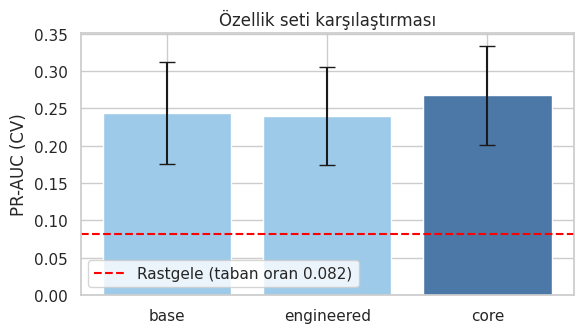

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(fs["feature_set"], fs["pr_auc"], yerr=fs["pr_auc_std"], capsize=6, color=["#9ecae9", "#9ecae9", "#4c78a8"])
ax.axhline(ytr.mean(), color="red", ls="--", label=f"Rastgele (taban oran {ytr.mean():.3f})"); ax.legend()
ax.set_ylabel("PR-AUC (CV)"); ax.set_title("Özellik seti karşılaştırması"); plt.tight_layout(); plt.show()

### Yorum — dürüst sonuç
1. **Üç set de aynı bantta** (farklar fold standart sapmasının çok altında). *Üretilen özellikler, Lojistik Regresyon'a ölçülebilir bir katkı sağlamadı.* Bunun makul nedeni: lojistik regresyon zaten `satisfaction`, `complaints` vb. sayaçları doğrusal kullanabiliyor; bayraklar ve toplamlar aynı bilgiyi tekrar ediyor.
2. **Sade `core` set en az diğerleri kadar iyi** (hatta sayısal olarak biraz daha iyi, ama bu fark da gürültü içinde).
3. **Karar kuralımız (parsimony / 1-SE):** Başarı fark etmiyorsa **en sade seti** seç. Daha az girdi = daha az hata riski, daha kolay API, daha kolay açıklama, daha az eksik veri sorunu. → `SELECTED_FEATURE_SET = "core"`.

> Bu, portföyünde gösterebileceğin değerli bir olgunluk işaretidir: *"Özellik ürettim, test ettim, işe yaramayanı modele koymadım."* Mülakatta "feature engineering ile skor ne kadar arttı?" diye sorulursa dürüst cevap: **bu veri setinde artmadı; sebebi şu.**

`add_features` kodda duruyor çünkü (a) farklı modeller/veri setlerinde değerli olabilir, (b) sonucu yeniden test edebilmen için.